<a href="https://colab.research.google.com/github/ReversePI78/-DevelRocket-AI-game-review-analysis/blob/main/18%EC%B0%A8%EC%8B%9C_%EB%A9%80%ED%8B%B0%ED%83%9C%EC%8A%A4%ED%81%AC%ED%94%84%EB%A1%AC%ED%94%84%ED%8A%B8%EC%8B%A4%EC%8A%B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 18차시: 멀티태스크 프롬프트 실습 (프로젝트)

**학습 목표**
- 17차시에서 배운 기법을 실제 리뷰 데이터에 적용할 수 있다
- 여러 리뷰를 반복 처리하는 파이프라인을 구축할 수 있다
- 분석 결과를 CSV 파일로 저장할 수 있다

---

## 1. 배경: 왜 자동화가 필요한가?

### 상황을 생각해봅시다

17차시에서 우리는 리뷰 하나를 분석하는 방법을 배웠습니다.

```
리뷰 1개 → LLM 호출 → 감성 + 키워드 + 요약
```

그런데... **실제로는 리뷰가 수백, 수천 개**입니다.

### 문제점

| 수동 방식 | 문제 |
|----------|------|
| 리뷰마다 복사-붙여넣기 | 시간 낭비 |
| 결과를 하나씩 정리 | 실수 가능성 |
| 중간에 에러 발생 | 처음부터 다시 |

### 해결책: 자동화 파이프라인

```
리뷰 100개 → 반복 처리 → 결과 자동 저장
```

이번 시간에 이 파이프라인을 직접 만들어봅니다!

---

## 2. 목표: 무엇을 만들 것인가?

### 최종 산출물

**입력**: 리뷰 텍스트가 담긴 CSV 파일

**출력**: 분석 결과가 추가된 CSV 파일

```
원본 CSV                    결과 CSV
┌─────────────┐            ┌─────────────────────────────────┐
│ review      │     →      │ review | sentiment | keywords   │
│ "Great..."  │            │ "Great.." | POSITIVE | graphics │
│ "Terrible" │            │ "Terrible" | NEGATIVE | bugs    │
└─────────────┘            └─────────────────────────────────┘
```

### 구체적 목표

1. 리뷰 20개를 자동으로 분석
2. 각 리뷰에서 감성, 키워드, 요약 추출
3. 결과를 CSV로 저장
4. 처리 현황 실시간 확인

---

## 3. 설계: 어떻게 접근할 것인가?

코드를 바로 작성하기 전에, **한글로 순서를 정리**해봅시다.

### 수도 코드 (Pseudocode)

```
1. 준비
   - API 키 불러오기
   - 클라이언트 설정하기

2. 분석 함수 만들기
   - 리뷰 하나를 받아서
   - LLM에게 분석 요청하고
   - 결과(감성, 키워드, 요약)를 반환

3. 데이터 준비
   - 샘플 리뷰 20개 준비하기

4. 반복 처리
   - 각 리뷰에 대해:
     - 분석 함수 호출
     - 결과 저장
     - 진행 상황 출력
     - (선택) 잠시 대기 (API 부하 방지)

5. 결과 저장
   - 모든 결과를 CSV로 저장
```

이제 이 순서대로 코드를 작성해봅시다!

---

## 4. 구현: 단계별 코드 작성

### 4-1. 준비 단계

> **(실습에서는 무료로 빠르게 쓸 수 있는 Groq의 gpt-oss-20b 모델을 사용합니다.)**

In [ ]:
# 수도 코드:
# 1. 필요한 라이브러리 설치
# 2. API 키 불러오기
# 3. 클라이언트 설정

# 라이브러리 설치
!pip install openai -q
print("설치 완료!")

설치 완료!


In [ ]:
# API 키 불러오기
from google.colab import userdata

api_key = userdata.get('GROQ_API_KEY')
print(f"키 확인: {'있음' if api_key else '없음'} (길이 {len(api_key or '')}자)")  # 키 일부도 출력하지 않음

키 확인: 있음 (길이 56자)


In [ ]:
# 클라이언트 설정
from openai import OpenAI

client = OpenAI(
    base_url="https://api.groq.com/openai/v1",
    api_key=api_key
)

print("클라이언트 준비 완료!")

클라이언트 준비 완료!


In [ ]:
MODEL="openai/gpt-oss-20b"

### 4-2. 분석 함수 만들기

17차시에서 배운 멀티태스크 분석 함수를 가져옵니다.

In [ ]:
# 수도 코드:
# 함수 정의: analyze_review(리뷰)
#   LLM에게 요청: 감성, 키워드, 요약을 JSON으로 달라고
#   응답을 JSON으로 파싱
#   파싱 실패하면 기본값 반환
#   성공하면 결과 반환

import json
import re

def analyze_review(review):
    """리뷰 하나를 분석해서 감성, 키워드, 요약을 반환"""

    # LLM에게 분석 요청
    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": """너는 게임 리뷰 분석 전문가야.
리뷰를 분석해서 다음 정보를 JSON 형식으로 추출해.

### 예시 ###
리뷰: "Amazing graphics and story, but multiplayer is broken."
return :
{
  "sentiment": "MIXED",
  "keywords": ["graphics", "story", "multiplayer"],
  "summary": "그래픽과 스토리는 좋지만 멀티플레이어가 문제"
}
주의 : 응답 처음에 json 넣지 말것. 결과를 바로 json변환할수 있게 내용만 담기
### 예시 끝 ###

반드시 JSON 형식으로만 답해."""
            },
            {"role": "user", "content": f"리뷰: {review}"}
        ],
        max_tokens=1024
    )

    # 응답 파싱 시도
    result_text = response.choices[0].message.content or ''
    # 응답이 ```json ... ``` 코드 블록으로 감싸져 오면 표시를 벗겨낸다
    cleaned = re.sub(r'^```(?:json)?\s*|\s*```$', '', result_text.strip())

    try:
        # JSON 파싱 성공
        parsed = json.loads(cleaned)
        return {
            "sentiment": parsed.get("sentiment", "UNKNOWN"),
            "keywords": ", ".join(parsed.get("keywords", [])),
            "summary": parsed.get("summary", "")
        }
    except json.JSONDecodeError:
        # 파싱 실패시 기본값
        print(f"    파싱 실패: {result_text}")
        return {
            "sentiment": "PARSE_ERROR",
            "keywords": "",
            "summary": result_text[:100]  # 원본 응답 일부 저장
        }

print("분석 함수 준비 완료!")

분석 함수 준비 완료!


In [ ]:
# 함수 테스트: 제대로 동작하는지 확인
test_review = "Great game with beautiful visuals, but crashes too often."
result = analyze_review(test_review)

print("=== 함수 테스트 ===")
print(f"입력: {test_review}")
print(f"감성: {result['sentiment']}")
print(f"키워드: {result['keywords']}")
print(f"요약: {result['summary']}")

=== 함수 테스트 ===
입력: Great game with beautiful visuals, but crashes too often.
감성: MIXED
키워드: visuals, crashes
요약: 아름다운 시각 효과는 좋지만 자주 크래시가 발생한다.


### 4-3. 샘플 데이터 준비

분석할 리뷰 20개를 준비합니다.

In [ ]:
# 수도 코드:
# 리뷰 리스트 만들기
# - 긍정 리뷰 몇 개
# - 부정 리뷰 몇 개
# - 혼합 리뷰 몇 개

sample_reviews = [
    # 긍정적 리뷰
    "Absolutely love this game! Best RPG I have played in years.",
    "10/10 would recommend. Amazing storyline and characters.",
    "Worth every penny. The graphics are stunning.",
    "Addictive gameplay. I have spent over 200 hours already.",
    "Perfect game for relaxing after work. Love the music too.",
    "Finally a game that lives up to the hype!",
    "The developers really care about the community. Great updates.",

    # 부정적 리뷰
    "Waste of money. Game crashes every 10 minutes.",
    "Do not buy. Full of bugs and the devs abandoned it.",
    "Terrible optimization. Unplayable on my PC.",
    "Boring and repetitive. Refunded after 1 hour.",
    "Pay to win garbage. Save your money.",
    "Server issues make multiplayer impossible.",

    # 혼합 리뷰
    "Good concept but poor execution. Needs more work.",
    "Fun gameplay but the story is forgettable.",
    "Beautiful graphics but shallow gameplay loop.",
    "Great potential but too many bugs right now.",
    "Decent game on sale. Not worth full price.",
    "Enjoyable single player but multiplayer is dead.",
    "Love the art style but hate the microtransactions."
]

print(f"샘플 리뷰 {len(sample_reviews)}개 준비 완료!")

샘플 리뷰 20개 준비 완료!


### 4-4. 반복 처리

이제 핵심 부분입니다. 모든 리뷰를 하나씩 처리합니다.

In [ ]:
# 수도 코드:
# 결과를 담을 빈 리스트 만들기
# 각 리뷰에 대해 반복:
#   진행 상황 출력 (몇 번째 처리 중인지)
#   분석 함수 호출
#   결과를 리스트에 추가
#   1초 대기 (API 부하 방지)
# 완료 메시지 출력

import time

# 결과를 담을 리스트
results = []

print("=== 리뷰 분석 시작 ===")
print(f"총 {len(sample_reviews)}개 리뷰를 분석합니다.")
print()

for i, review in enumerate(sample_reviews, 1):
    # 진행 상황 출력
    print(f"[{i}/{len(sample_reviews)}] 분석 중...")

    # 분석 실행
    analysis = analyze_review(review)

    # 결과 저장 (원본 리뷰 + 분석 결과)
    results.append({
        "review": review,
        "sentiment": analysis["sentiment"],
        "keywords": analysis["keywords"],
        "summary": analysis["summary"]
    })

    # 간단한 결과 출력
    print(f"    → {analysis['sentiment']}")

    # API 부하 방지 (1초 대기)
    if i < len(sample_reviews):  # 마지막이 아니면 대기
        time.sleep(1)

print()
print(f"=== 완료! {len(results)}개 리뷰 분석 완료 ===")

=== 리뷰 분석 시작 ===
총 20개 리뷰를 분석합니다.

[1/20] 분석 중...
    → POSITIVE
[2/20] 분석 중...
    → POSITIVE
[3/20] 분석 중...
    → POSITIVE
[4/20] 분석 중...
    → POSITIVE
[5/20] 분석 중...
    → POSITIVE
[6/20] 분석 중...
    → POSITIVE
[7/20] 분석 중...
    → POSITIVE
[8/20] 분석 중...
    → NEGATIVE
[9/20] 분석 중...
    → NEGATIVE
[10/20] 분석 중...
    → NEGATIVE
[11/20] 분석 중...
    → NEGATIVE
[12/20] 분석 중...
    → NEGATIVE
[13/20] 분석 중...
    → NEGATIVE
[14/20] 분석 중...
    → MIXED
[15/20] 분석 중...
    → MIXED
[16/20] 분석 중...
    → MIXED
[17/20] 분석 중...
    → MIXED
[18/20] 분석 중...
    → MIXED
[19/20] 분석 중...
    → MIXED
[20/20] 분석 중...
    → MIXED

=== 완료! 20개 리뷰 분석 완료 ===


### 4-5. 결과 확인

In [ ]:
# 결과 요약 통계
from collections import Counter

# 감성별 개수 세기
sentiment_counts = Counter(r["sentiment"] for r in results)

print("=== 분석 결과 요약 ===")
print(f"총 리뷰: {len(results)}개")
print()
print("감성 분포:")
for sentiment, count in sentiment_counts.most_common():
    percentage = count / len(results) * 100
    print(f"  {sentiment}: {count}개 ({percentage:.1f}%)")

=== 분석 결과 요약 ===
총 리뷰: 20개

감성 분포:
  POSITIVE: 7개 (35.0%)
  MIXED: 7개 (35.0%)
  NEGATIVE: 6개 (30.0%)


In [ ]:
# 상세 결과 출력 (처음 5개만)
print("=== 상세 결과 (처음 5개) ===")
print()

for i, r in enumerate(results[:5], 1):
    print(f"--- 리뷰 {i} ---")
    print(f"원본: {r['review'][:50]}...")
    print(f"감성: {r['sentiment']}")
    print(f"키워드: {r['keywords']}")
    print(f"요약: {r['summary']}")
    print()

=== 상세 결과 (처음 5개) ===

--- 리뷰 1 ---
원본: Absolutely love this game! Best RPG I have played ...
감성: POSITIVE
키워드: RPG, game
요약: 이 게임을 정말 좋아하며, 지난 몇 년 중 최고의 RPG입니다.

--- 리뷰 2 ---
원본: 10/10 would recommend. Amazing storyline and chara...
감성: POSITIVE
키워드: storyline, characters
요약: 스토리와 캐릭터가 훌륭해서 10/10 추천

--- 리뷰 3 ---
원본: Worth every penny. The graphics are stunning....
감성: POSITIVE
키워드: graphics, value
요약: 그래픽이 멋지고 가성비가 뛰어나다

--- 리뷰 4 ---
원본: Addictive gameplay. I have spent over 200 hours al...
감성: POSITIVE
키워드: addictive gameplay, hours
요약: 게임이 중독적이며 이미 200시간 이상 플레이했다.

--- 리뷰 5 ---
원본: Perfect game for relaxing after work. Love the mus...
감성: POSITIVE
키워드: relaxing, music
요약: 일 후 휴식을 위해 완벽한 게임, 음악도 좋아요



### 4-6. CSV로 저장

분석 결과를 파일로 저장합니다.

In [ ]:
# 수도 코드:
# pandas로 DataFrame 만들기
# CSV 파일로 저장
# 저장 완료 메시지 출력

import pandas as pd

# DataFrame 생성
df = pd.DataFrame(results)

# CSV로 저장
output_filename = "review_analysis_results.csv"
df.to_csv(output_filename, index=False, encoding="utf-8-sig")

print(f"결과가 '{output_filename}'에 저장되었습니다!")
print(f"총 {len(df)}개 행, {len(df.columns)}개 열")

결과가 'review_analysis_results.csv'에 저장되었습니다!
총 20개 행, 4개 열


In [ ]:
# 저장된 파일 미리보기
df.head()

,review,sentiment,keywords,summary
0,Absolutely love this game! Best RPG I have pla...,POSITIVE,"RPG, game","이 게임을 정말 좋아하며, 지난 몇 년 중 최고의 RPG입니다."
1,10/10 would recommend. Amazing storyline and c...,POSITIVE,"storyline, characters",스토리와 캐릭터가 훌륭해서 10/10 추천
2,Worth every penny. The graphics are stunning.,POSITIVE,"graphics, value",그래픽이 멋지고 가성비가 뛰어나다
3,Addictive gameplay. I have spent over 200 hour...,POSITIVE,"addictive gameplay, hours",게임이 중독적이며 이미 200시간 이상 플레이했다.
4,Perfect game for relaxing after work. Love the...,POSITIVE,"relaxing, music","일 후 휴식을 위해 완벽한 게임, 음악도 좋아요"


In [ ]:
# Colab에서 파일 다운로드
from google.colab import files

files.download(output_filename)
print("다운로드가 시작됩니다!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

다운로드가 시작됩니다!


---

## 5. 도전 과제

기본 파이프라인을 완성했습니다. 추가로 도전해볼 것들:

### 도전 1: 에러 처리 추가

API 호출 중 에러가 발생하면 어떻게 될까요?

In [ ]:
# 힌트: try-except로 에러 처리

def analyze_review_safe(review):
    """에러 처리가 추가된 버전"""
    try:
        return analyze_review(review)
    except Exception as e:
        print(f"    에러 발생: {e}")
        return {
            "sentiment": "ERROR",
            "keywords": "",
            "summary": str(e)
        }

print("안전한 분석 함수 정의 완료!")

안전한 분석 함수 정의 완료!


### 도전 2: 진행률 표시 개선

tqdm 라이브러리로 프로그레스 바를 표시해봅시다.

In [ ]:
# tqdm 설치 및 사용
!pip install tqdm -q

from tqdm import tqdm

# 예시: tqdm으로 반복문 감싸기
# for review in tqdm(sample_reviews, desc="분석 중"):
#     analyze_review(review)

print("tqdm 설치 완료! 위 코드를 참고해서 적용해보세요.")

tqdm 설치 완료! 위 코드를 참고해서 적용해보세요.


### 도전 3: 실제 데이터로 분석

8차시에서 수집한 실제 Steam 리뷰 데이터가 있다면, 그 데이터로 분석해보세요!

In [ ]:
# 힌트: CSV 파일에서 리뷰 불러오기

# 파일 업로드
# from google.colab import files
# uploaded = files.upload()

# CSV 읽기
# df_reviews = pd.read_csv("your_reviews.csv")
# reviews_to_analyze = df_reviews["review"].tolist()[:20]  # 처음 20개만

print("위 코드를 참고해서 실제 데이터로 분석해보세요!")

위 코드를 참고해서 실제 데이터로 분석해보세요!


## 6. 실제 데이터 분석: 한국어 리뷰 20건 (도전 1~3 적용)

위 파이프라인을 영어 샘플이 아닌 **한국어 리뷰**에 적용합니다.

- **데이터**: 원래 8차시부터 써 온 스타듀 밸리 리뷰를 Steam 리뷰 API로 받으려 했으나, 2026-11-23 현재 API가 JSON 대신 Steam 첫 화면으로 리다이렉트되어 받을 수 없었습니다. 대신 강의 자료의 `sample_reviews.csv`(4차시 실습 데이터, 한국어 리뷰 500건, 추천 여부 포함)를 왼쪽 파일 패널로 올려 사용합니다.
- **표본 20건**: 같은 문장이 반복되는 데이터라 중복을 제거하고, 10자 이상 리뷰 중 **추천 14건 + 비추천 6건**을 뽑습니다(`random_state=42`).
- **도전 1** 에러 처리: `analyze_review_safe`로 에러가 나도 멈추지 않고 `ERROR`로 기록 후 계속
- **도전 2** 진행률: `tqdm` 프로그레스 바 + 호출 사이 1초 대기
- **도전 3** 실제 데이터: 결과를 `korean_review_analysis_20.csv`로 저장하고, LLM 감성과 리뷰의 추천 여부를 비교

In [22]:
# 강의 자료 sample_reviews.csv(4차시 실습 데이터, 한국어 리뷰 500건) 불러오기 - 왼쪽 파일 패널로 업로드
# Steam 리뷰 API가 2026-11-23 현재 JSON 대신 Steam 첫 화면으로 리다이렉트되어 스타듀 밸리 리뷰를 실시간으로 받을 수 없어 대체함
pool = pd.read_csv('sample_reviews.csv').rename(columns={'review_text': 'review', 'recommended': 'steam_recommended'})
print(f"불러온 리뷰: {len(pool)}건, 고유 문장 {pool['review'].nunique()}개, 추천 비율 {pool['steam_recommended'].mean() * 100:.1f}%")

# 같은 문장이 반복되는 실습 데이터라 문장 기준으로 중복 제거 후, 10자 이상만 사용
pool['review'] = pool['review'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
pool = pool[pool['review'].str.len() >= 10].drop_duplicates('review')
print(f"중복 제거·10자 이상: 추천 {pool['steam_recommended'].sum()}건, 비추천 {(~pool['steam_recommended']).sum()}건")

pos = pool[pool['steam_recommended']]
neg = pool[~pool['steam_recommended']]
sample20 = pd.concat([pos.sample(min(14, len(pos)), random_state=42),
                      neg.sample(min(6, len(neg)), random_state=42)]).reset_index(drop=True)
print(f"분석 표본: {len(sample20)}건 (추천 {sample20['steam_recommended'].sum()} / 비추천 {(~sample20['steam_recommended']).sum()})")
sample20[['review', 'steam_recommended']]

불러온 리뷰: 500건, 고유 문장 82개, 추천 비율 63.4%
중복 제거·10자 이상: 추천 49건, 비추천 33건
분석 표본: 20건 (추천 14 / 비추천 6)


,review,steam_recommended
0,밸런스가 잘 잡혀있어요. 공정한 게임.,True
1,무난해요. 시간 때우기엔 괜찮아요.,True
2,정말 재밌어요! 222시간 넘게 플레이했는데 아직도 질리지 않아요.,True
3,엔딩 보고 여운이 오래 남았어요.,True
4,음악이 정말 좋아요. OST 따로 살 정도로.,True
5,정말 재밌어요! 382시간 넘게 플레이했는데 아직도 질리지 않아요.,True
6,가성비 최고의 게임. 이 가격에 이 퀄리티라니.,True
7,조작감이 좋아요. 손맛이 있달까.,True
8,좋은 점도 있고 아쉬운 점도 있어요. 세일 때 사면 괜찮을 듯.,True
9,세이브 시스템이 편해요. 자주 저장됨.,True


In [23]:
# 20건 반복 분석: tqdm 진행률 + 에러가 나도 계속(analyze_review_safe) + 호출 사이 1초 대기
real_results = []
for i, row in enumerate(tqdm(sample20.itertuples(), total=len(sample20), desc='한국어 리뷰 분석')):
    analysis = analyze_review_safe(row.review)
    real_results.append({'review': row.review, 'sentiment': analysis['sentiment'], 'keywords': analysis['keywords'],
                         'summary': analysis['summary'], 'steam_recommended': row.steam_recommended})
    if i < len(sample20) - 1:
        time.sleep(1)

real_df = pd.DataFrame(real_results)
real_df.to_csv('korean_review_analysis_20.csv', index=False, encoding='utf-8-sig')
print(f"저장 완료: korean_review_analysis_20.csv / {len(real_df)}행, 컬럼 {real_df.columns.tolist()}")

한국어 리뷰 분석: 100%|██████████| 20/20 [00:28<00:00,  1.45s/it]

저장 완료: korean_review_analysis_20.csv / 20행, 컬럼 ['review', 'sentiment', 'keywords', 'summary', 'steam_recommended']


=== 감성 분포 ===
  POSITIVE: 13개 (65.0%)
  NEGATIVE: 5개 (25.0%)
  MIXED: 1개 (5.0%)
  NEUTRAL: 1개 (5.0%)

=== 처리 결과 ===
  성공: 20개 (100%) / 실패: 0개

=== 추천 여부 × LLM 감성 ===
sentiment          MIXED  NEGATIVE  NEUTRAL  POSITIVE
steam_recommended                                    
비추천                    0         5        1         0
추천                     1         0        0        13

POSITIVE/NEGATIVE로 판정한 18건 중 추천 여부와 일치: 100%
MIXED로 판정: 1건 (추천 1 / 비추천 0)


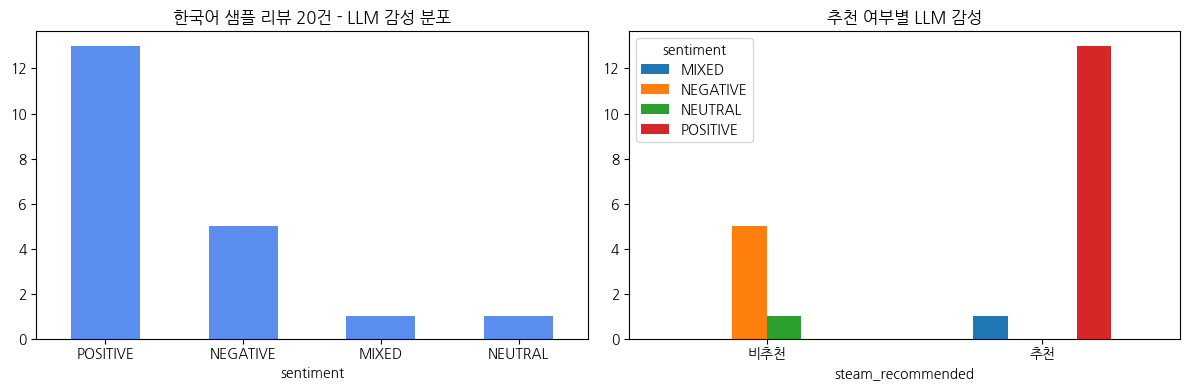

In [24]:
# 감성 분포 통계 + 성공률 + Steam 추천 여부와 비교
!pip install -q koreanize-matplotlib
import koreanize_matplotlib
import matplotlib.pyplot as plt

dist = real_df['sentiment'].value_counts()
print("=== 감성 분포 ===")
for s, c in dist.items():
    print(f"  {s}: {c}개 ({c / len(real_df) * 100:.1f}%)")

ok = ~real_df['sentiment'].isin(['PARSE_ERROR', 'ERROR', 'UNKNOWN'])
print(f"\n=== 처리 결과 ===\n  성공: {ok.sum()}개 ({ok.mean() * 100:.0f}%) / 실패: {(~ok).sum()}개")

print("\n=== 추천 여부 × LLM 감성 ===")
print(pd.crosstab(real_df['steam_recommended'].map({True: '추천', False: '비추천'}), real_df['sentiment']).to_string())
clear = real_df[real_df['sentiment'].isin(['POSITIVE', 'NEGATIVE'])]
agree = ((clear['sentiment'] == 'POSITIVE') == clear['steam_recommended']).mean() * 100 if len(clear) else 0
print(f"\nPOSITIVE/NEGATIVE로 판정한 {len(clear)}건 중 추천 여부와 일치: {agree:.0f}%")
print(f"MIXED로 판정: {(real_df['sentiment'] == 'MIXED').sum()}건 (추천 {((real_df['sentiment'] == 'MIXED') & real_df['steam_recommended']).sum()} / 비추천 {((real_df['sentiment'] == 'MIXED') & ~real_df['steam_recommended']).sum()})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dist.plot(kind='bar', ax=axes[0], rot=0, color='#5B8DEF')
axes[0].set_title('한국어 샘플 리뷰 20건 - LLM 감성 분포')
pd.crosstab(real_df['steam_recommended'].map({True: '추천', False: '비추천'}), real_df['sentiment']).plot(kind='bar', ax=axes[1], rot=0)
axes[1].set_title('추천 여부별 LLM 감성')
plt.tight_layout()
plt.show()

In [25]:
# 분석 결과 상세 (리뷰는 앞 60자만)
pd.set_option('display.max_colwidth', 80)
real_df.assign(review=real_df['review'].str[:60])[['review', 'steam_recommended', 'sentiment', 'keywords', 'summary']]

,review,steam_recommended,sentiment,keywords,summary
0,밸런스가 잘 잡혀있어요. 공정한 게임.,True,POSITIVE,"balance, fair, game",밸런스가 잘 잡혀 공정한 게임
1,무난해요. 시간 때우기엔 괜찮아요.,True,POSITIVE,"무난, 시간 때우기, 괜찮아",무난하며 시간 때우기에 적당하다.
2,정말 재밌어요! 222시간 넘게 플레이했는데 아직도 질리지 않아요.,True,POSITIVE,"재미, 플레이 시간, 222시간",플레이 시간이 222시간을 넘겼지만 여전히 질리지 않는 즐거움
3,엔딩 보고 여운이 오래 남았어요.,True,POSITIVE,"엔딩, 여운",엔딩을 보니 여운이 오래 남았다.
4,음악이 정말 좋아요. OST 따로 살 정도로.,True,POSITIVE,"음악, OST",음악이 정말 좋아 OST를 따로 구매할 정도다
5,정말 재밌어요! 382시간 넘게 플레이했는데 아직도 질리지 않아요.,True,POSITIVE,"재미, 플레이 시간, 지속성",382시간 넘게 플레이해도 질리지 않아 계속 즐거움
6,가성비 최고의 게임. 이 가격에 이 퀄리티라니.,True,POSITIVE,"가성비, 게임, 가격, 퀄리티",이 게임은 가격 대비 최고의 퀄리티를 제공한다.
7,조작감이 좋아요. 손맛이 있달까.,True,POSITIVE,"조작감, 손맛",조작감이 좋고 손맛이 있는 게임
8,좋은 점도 있고 아쉬운 점도 있어요. 세일 때 사면 괜찮을 듯.,True,MIXED,"좋은 점, 아쉬운 점, 세일, 사면",좋은 점과 아쉬운 점이 있지만 세일 때 구입하면 괜찮을 것 같음
9,세이브 시스템이 편해요. 자주 저장됨.,True,POSITIVE,"세이브 시스템, 저장",저장 시스템이 편리하고 자주 저장됩니다.


## 7. 결과 메모

**[적용 결과]**
- 수정 2건: API 키는 앞부분도 출력하지 않고 길이만 표시, 응답의 ```json 코드 블록 표시를 벗겨낸 뒤 파싱 → 원본 노트북에서 PARSE_ERROR였던 함수 테스트가 MIXED로 정상 파싱
- 영어 샘플 20건(4-4): 성공 20건(100%), POSITIVE 7 / NEGATIVE 6 / MIXED 7 → 샘플을 만든 의도(긍정 7·부정 6·혼합 7)와 20건 모두 일치, `review_analysis_results.csv` 저장
- 한국어 리뷰 20건(6장, 도전 1~3 적용): 성공 20건(100%), POSITIVE 13 (65%) / NEGATIVE 5 (25%) / MIXED 1 (5%) / NEUTRAL 1 (5%), 20건 처리 약 28초(리뷰당 1.45초, 대기 1초 포함), `korean_review_analysis_20.csv` 저장
- 데이터: Steam 리뷰 API가 JSON 대신 Steam 첫 화면으로 리다이렉트되어 스타듀 밸리 리뷰 대신 강의 자료 `sample_reviews.csv`(500건 중 고유 문장 82개)에서 추천 14 + 비추천 6건을 사용

**[발견한 점]**
1. **파싱 한 줄이 성패를 가른다**: 모델은 "json을 넣지 말라"는 지시가 있어도 코드 블록으로 감싸 답할 때가 있다. 코드 블록 표시를 벗기는 정규식 한 줄로 실패율이 0%가 됐다. 프롬프트 지시보다 받는 쪽 코드에서 방어하는 편이 확실하다.
2. **추천 여부와의 일치도가 높다**: POSITIVE/NEGATIVE로 판정한 18건은 모두 리뷰의 추천 여부와 일치했다(100%). 나머지 2건은 '좋은 점도 있고 아쉬운 점도 있어요. 세일 때 사면 괜찮을 듯'(추천 → MIXED), '그럭저럭 할만해요. 특별히 좋지도 나쁘지도 않아요'(비추천 → NEUTRAL)로, 추천 버튼만으로는 드러나지 않는 애매한 의견을 LLM이 구분했다.
3. **라벨이 정해져 있지 않다**: 프롬프트 예시에 MIXED만 보여주고 허용 라벨 목록을 주지 않아, 모델이 스스로 NEUTRAL을 만들어 냈다. 다음 단계에서는 "POSITIVE/NEGATIVE/MIXED/NEUTRAL 중 하나"처럼 라벨을 명시해야 집계가 안정적이다.
4. **키워드 언어가 섞인다**: 예시가 영어라 일부 한국어 리뷰도 'balance, fair, game', 'average, okay, neutral'처럼 영어 키워드가 나왔다. 한국어 리뷰를 분석할 때는 한국어 예시를 넣거나 "키워드는 리뷰와 같은 언어로" 같은 규칙이 필요하다.
5. **'무난해요'는 긍정일까**: '무난해요. 시간 때우기엔 괜찮아요'는 POSITIVE로 판정됐다. 추천 리뷰이긴 하지만 열의가 낮은 의견이라, 감성 강도(점수)까지 받으면 더 세밀하게 나눌 수 있다.

---

## 정리

### 이번 시간에 만든 것

```
리뷰 20개 → 자동 분석 → CSV 저장
```

### 핵심 패턴

```python
# 1. 분석 함수 정의
def analyze_review(review):
    # LLM 호출 + JSON 파싱
    return {"sentiment": ..., "keywords": ..., "summary": ...}

# 2. 반복 처리
results = []
for review in reviews:
    result = analyze_review(review)
    results.append(result)
    time.sleep(1)  # API 부하 방지

# 3. 결과 저장
df = pd.DataFrame(results)
df.to_csv("output.csv")
```

### 배운 점

1. **수도 코드 먼저**: 코드 작성 전에 한글로 순서 정리
2. **단계별 구현**: 한 번에 다 만들지 않고 조금씩
3. **테스트 먼저**: 함수 만들면 바로 테스트
4. **에러 대비**: API 호출은 실패할 수 있음

### 다음 시간 예고

19차시에서는 **프롬프트 최적화**를 다룹니다.
- 토큰 비용 절약하기
- 응답 품질 높이기
- 일관성 있는 결과 얻기